In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL
from getpass import getpass
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully!")

Libraries imported successfully!


In [41]:
username = "postgres"
password = getpass("Enter your PostgreSQL password: ")

connection_url = URL.create(
    "postgresql+psycopg2",
    username=username,
    password=password,
    host="localhost",
    port=5432,
    database="customer_behavior"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Successfully connected to PostgreSQL!")

Enter your PostgreSQL password:  ········


Successfully connected to PostgreSQL!


In [80]:
# Read the cleaned table created in the original notebook
df = pd.read_sql("SELECT * FROM customer", engine)

print("Data loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Data loaded successfully!
Dataset shape: (3900, 19)


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.10,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.10,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.10,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.50,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.70,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


In [81]:
analysis_df = df.copy()

print("Analysis copy created.")
print("Rows:", analysis_df.shape[0])
print("Columns:", analysis_df.shape[1])

Analysis copy created.
Rows: 3900
Columns: 19


In [82]:
print("Column names:")
display(pd.DataFrame({"column_name": analysis_df.columns}))

print("\nDataset information:")
analysis_df.info()


Column names:


,column_name
0,customer_id
1,age
2,gender
3,item_purchased
4,category
5,purchase_amount
6,location
7,size
8,color
9,season



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              3900 non-null   int64  
 1   age                      3900 non-null   int64  
 2   gender                   3900 non-null   str    
 3   item_purchased           3900 non-null   str    
 4   category                 3900 non-null   str    
 5   purchase_amount          3900 non-null   int64  
 6   location                 3900 non-null   str    
 7   size                     3900 non-null   str    
 8   color                    3900 non-null   str    
 9   season                   3900 non-null   str    
 10  review_rating            3900 non-null   float64
 11  subscription_status      3900 non-null   str    
 12  shipping_type            3900 non-null   str    
 13  discount_applied         3900 non-null   str    
 14  previous_purc

In [83]:
missing_summary = pd.DataFrame({
    "missing_count": analysis_df.isnull().sum(),
    "missing_percentage": (analysis_df.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_summary)

,missing_count,missing_percentage
customer_id,0,0.00
age,0,0.00
gender,0,0.00
item_purchased,0,0.00
category,0,0.00
purchase_amount,0,0.00
location,0,0.00
size,0,0.00
color,0,0.00
season,0,0.00


In [84]:
duplicate_rows = analysis_df.duplicated().sum()
print("Complete duplicate rows:", duplicate_rows)

Complete duplicate rows: 0


In [85]:
duplicate_ids = analysis_df["customer_id"].duplicated().sum()
print("Duplicate customer IDs:", duplicate_ids)

if duplicate_ids > 0:
    display(
        analysis_df[analysis_df["customer_id"].duplicated(keep=False)]
        .sort_values("customer_id")
        .head(20)
    )

Duplicate customer IDs: 0


In [131]:
categorical_columns = analysis_df.select_dtypes(
    include=["str", "object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}: {analysis_df[column].nunique()} unique values")
    print(sorted(analysis_df[column].dropna().astype(str).unique()))


gender: 2 unique values
['Female', 'Male']

item_purchased: 25 unique values
['Backpack', 'Belt', 'Blouse', 'Boots', 'Coat', 'Dress', 'Gloves', 'Handbag', 'Hat', 'Hoodie', 'Jacket', 'Jeans', 'Jewelry', 'Pants', 'Sandals', 'Scarf', 'Shirt', 'Shoes', 'Shorts', 'Skirt', 'Sneakers', 'Socks', 'Sunglasses', 'Sweater', 'T-shirt']

category: 4 unique values
['Accessories', 'Clothing', 'Footwear', 'Outerwear']

location: 50 unique values
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia'

In [87]:
numeric_columns = analysis_df.select_dtypes(include=np.number).columns
display(analysis_df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
customer_id,"3,900.00","1,950.50","1,125.98",1.00,975.75,"1,950.50","2,925.25","3,900.00"
age,"3,900.00",44.07,15.21,18.00,31.00,44.00,57.00,70.00
purchase_amount,"3,900.00",59.76,23.69,20.00,39.00,60.00,81.00,100.00
review_rating,"3,900.00",3.75,0.71,2.50,3.10,3.80,4.40,5.00
previous_purchases,"3,900.00",25.35,14.45,1.00,13.00,25.00,38.00,50.00
purchase_frequency_days,"3,900.00",89.13,119.04,7.00,14.00,30.00,90.00,365.00


In [88]:
# Basic logical checks. These identify suspicious values; they do not change the data.
checks = {
    "age less than or equal to zero": (analysis_df["age"] <= 0).sum(),
    "negative purchase amount": (analysis_df["purchase_amount"] < 0).sum(),
    "review rating below 1": (analysis_df["review_rating"] < 1).sum(),
    "review rating above 5": (analysis_df["review_rating"] > 5).sum(),
    "negative previous purchases": (analysis_df["previous_purchases"] < 0).sum()
}

display(pd.DataFrame(list(checks.items()), columns=["validation_check", "records_flagged"]))

,validation_check,records_flagged
0,age less than or equal to zero,0
1,negative purchase amount,0
2,review rating below 1,0
3,review rating above 5,0
4,negative previous purchases,0


In [89]:
outlier_rows = []

for column in ["age", "purchase_amount", "review_rating", "previous_purchases"]:
    q1 = analysis_df[column].quantile(0.25)
    q3 = analysis_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((analysis_df[column] < lower_bound) | (analysis_df[column] > upper_bound)).sum()

    outlier_rows.append({
        "column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(count)
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
0,age,31.00,57.00,26.00,-8.00,96.00,0
1,purchase_amount,39.00,81.00,42.00,-24.00,144.00,0
2,review_rating,3.10,4.40,1.30,1.15,6.35,0
3,previous_purchases,13.00,38.00,25.00,-24.50,75.50,0


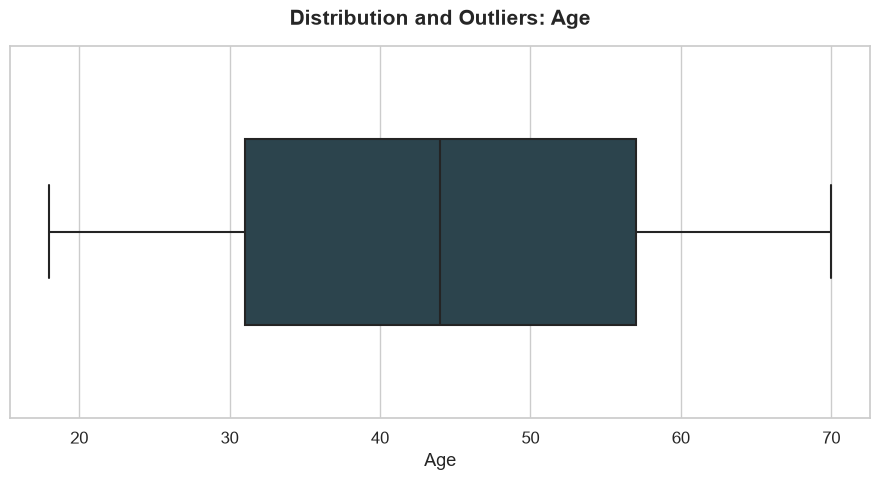

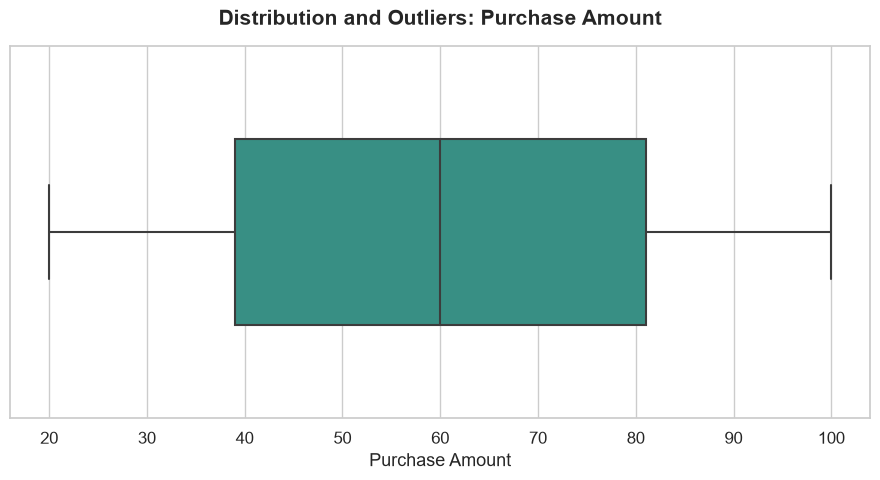

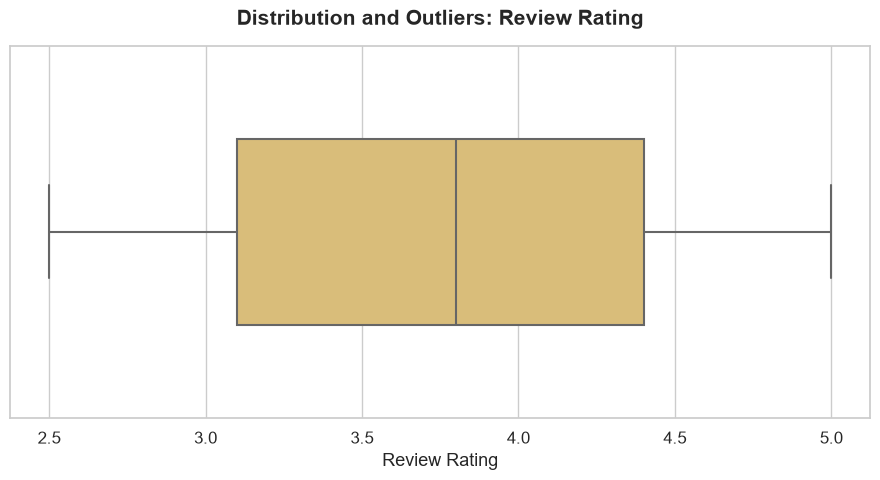

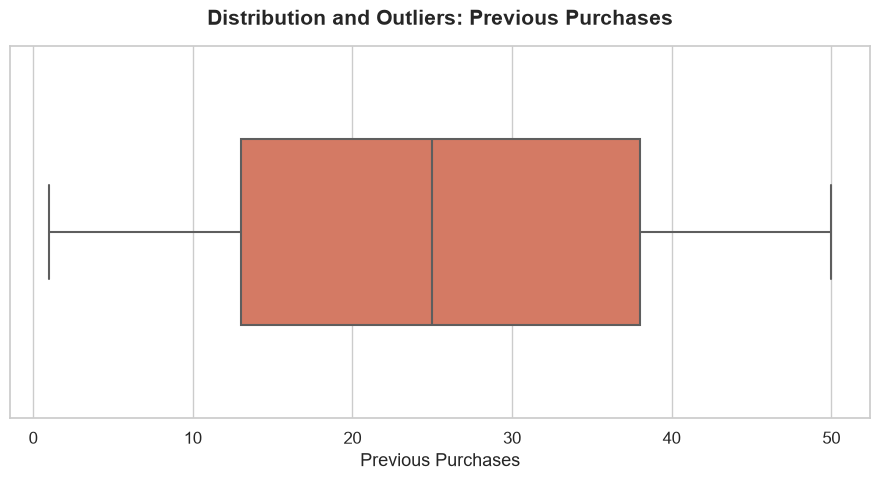

In [116]:
# VISUALIZE DISTRIBUTIONS AND POTENTIAL OUTLIERS

boxplot_colors = {
    "age": "#264653",                 # Navy
    "purchase_amount": "#2A9D8F",     # Teal
    "review_rating": "#E9C46A",       # Gold
    "previous_purchases": "#E76F51"   # Coral
}

for column in ["age", "purchase_amount", "review_rating", "previous_purchases"]:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        x=analysis_df[column],
        color=boxplot_colors[column],
        width=0.5,
        linewidth=1.5,
        flierprops={
            "marker": "o",
            "markerfacecolor": "#F4A261",
            "markeredgecolor": "#264653",
            "markersize": 5
        }
    )

    plt.title(
        f"Distribution and Outliers: {column.replace('_', ' ').title()}",
        fontweight="bold",
        pad=15
    )

    plt.xlabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

In [91]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total purchase records",
        "Unique customer IDs",
        "Total revenue",
        "Average purchase amount",
        "Median purchase amount",
        "Average review rating",
        "Number of products",
        "Number of categories"
    ],
    "Value": [
        len(analysis_df),
        analysis_df["customer_id"].nunique(),
        analysis_df["purchase_amount"].sum(),
        analysis_df["purchase_amount"].mean(),
        analysis_df["purchase_amount"].median(),
        analysis_df["review_rating"].mean(),
        analysis_df["item_purchased"].nunique(),
        analysis_df["category"].nunique()
    ]
})

display(kpi_summary.round(2))

,Metric,Value
0,Total purchase records,"3,900.00"
1,Unique customer IDs,"3,900.00"
2,Total revenue,"233,081.00"
3,Average purchase amount,59.76
4,Median purchase amount,60.00
5,Average review rating,3.75
6,Number of products,25.00
7,Number of categories,4.00


In [92]:
gender_analysis = analysis_df.groupby("gender", observed=False).agg(
    customer_count=("customer_id", "nunique"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean"),
    average_rating=("review_rating", "mean")
).reset_index()

gender_analysis["customer_percentage"] = (
    gender_analysis["customer_count"] / analysis_df["customer_id"].nunique() * 100
)

display(gender_analysis.round(2))

,gender,customer_count,total_revenue,average_purchase,average_rating,customer_percentage
0,Female,1248,75191,60.25,3.74,32.00
1,Male,2652,157890,59.54,3.75,68.00


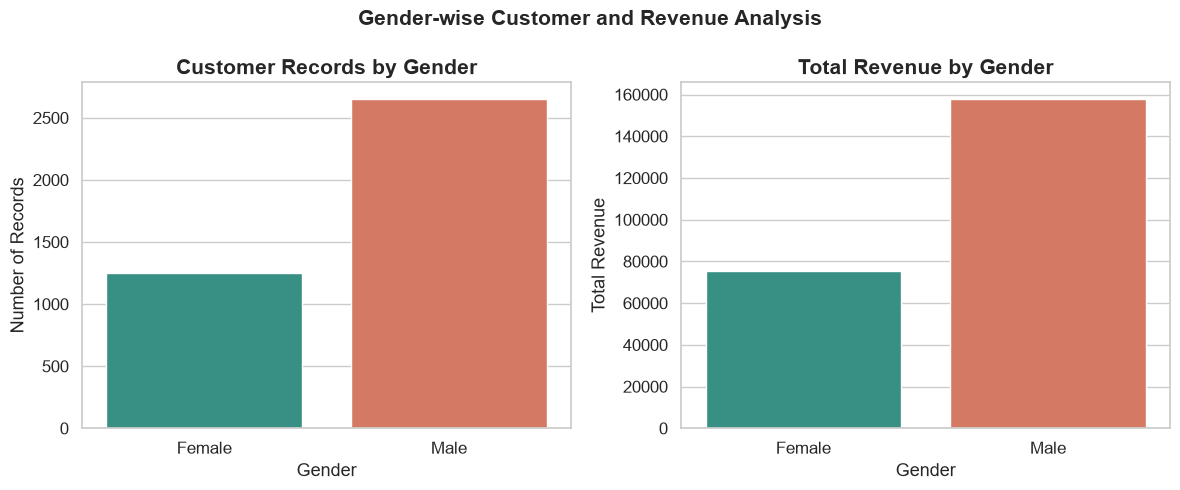

In [117]:
# CUSTOMER DEMOGRAPHICS AND REVENUE BY GENDER

gender_colors = {
    "Female": "#2A9D8F",  # Teal
    "Male": "#E76F51"     # Coral
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Customer records by gender
sns.countplot(
    data=analysis_df,
    x="gender",
    hue="gender",
    palette=gender_colors,
    order=["Female", "Male"],
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Records by Gender", fontweight="bold")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Records")

# 2. Total revenue by gender
sns.barplot(
    data=gender_analysis,
    x="gender",
    y="total_revenue",
    hue="gender",
    palette=gender_colors,
    order=["Female", "Male"],
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Total Revenue by Gender", fontweight="bold")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Total Revenue")

plt.suptitle("Gender-wise Customer and Revenue Analysis",
             fontsize=15, fontweight="bold")

plt.tight_layout()
plt.show()

In [94]:
print("Age statistics:")
display(analysis_df["age"].describe().to_frame().round(2))

age_group_analysis = analysis_df.groupby("age_group", observed=False).agg(
    customer_count=("customer_id", "nunique"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean"),
    average_rating=("review_rating", "mean")
).reset_index()

age_group_analysis["customer_percentage"] = (
    age_group_analysis["customer_count"] / analysis_df["customer_id"].nunique() * 100
)

display(age_group_analysis.round(2))

Age statistics:


,age
count,"3,900.00"
mean,44.07
std,15.21
min,18.00
25%,31.00
50%,44.00
75%,57.00
max,70.00


,age_group,customer_count,total_revenue,average_purchase,average_rating,customer_percentage
0,Adult,942,55978,59.42,3.73,24.15
1,Middle-aged,986,59197,60.04,3.71,25.28
2,Senior,944,55763,59.07,3.75,24.21
3,Young Adult,1028,62143,60.45,3.80,26.36


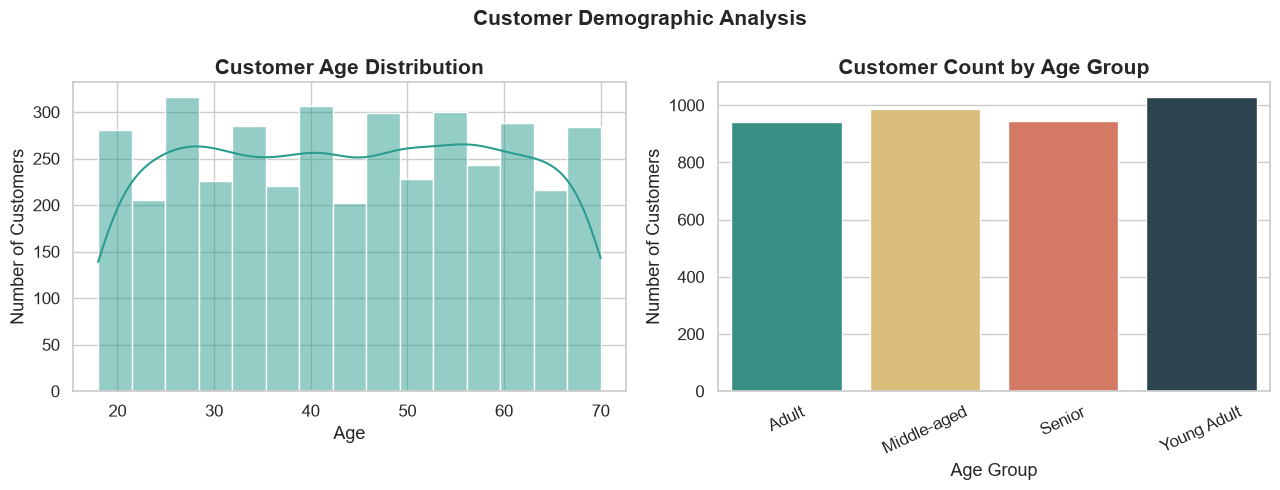

In [118]:
# CUSTOMER AGE DISTRIBUTION AND AGE GROUP ANALYSIS

age_colors = {
    "Young Adult": "#264653",  # Navy
    "Adult": "#2A9D8F",        # Teal
    "Middle-aged": "#E9C46A",  # Gold
    "Senior": "#E76F51"        # Coral
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Customer age distribution
sns.histplot(
    data=analysis_df,
    x="age",
    bins=15,
    kde=True,
    color="#2A9D8F",
    edgecolor="white",
    ax=axes[0]
)

axes[0].set_title("Customer Age Distribution", fontweight="bold")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Customers")

# 2. Customer count by age group
sns.barplot(
    data=age_group_analysis,
    x="age_group",
    y="customer_count",
    hue="age_group",
    palette=age_colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Customer Count by Age Group", fontweight="bold")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Number of Customers")
axes[1].tick_params(axis="x", rotation=25)

plt.suptitle(
    "Customer Demographic Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [96]:
spending_summary = analysis_df["purchase_amount"].agg(
    ["count", "sum", "mean", "median", "std", "min", "max"]
).to_frame(name="purchase_amount")

display(spending_summary.round(2))

,purchase_amount
count,"3,900.00"
sum,"233,081.00"
mean,59.76
median,60.00
std,23.69
min,20.00
max,100.00


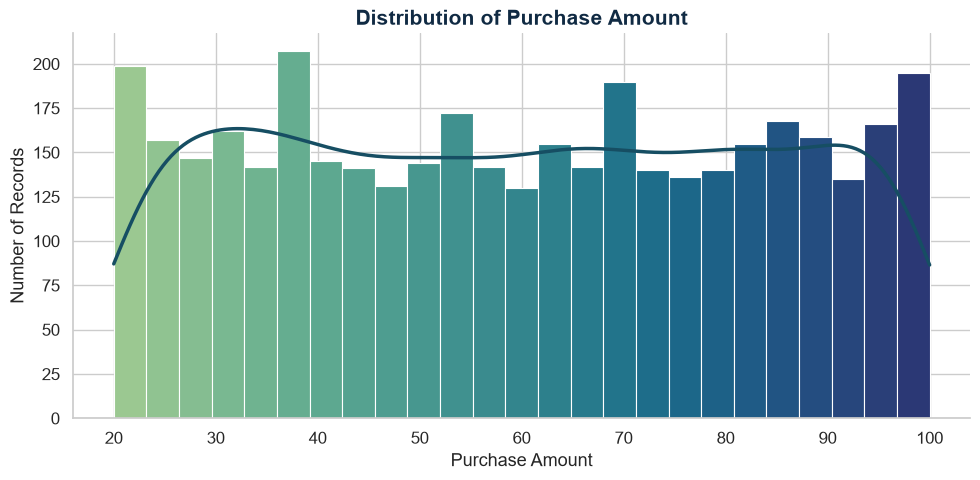

In [120]:
# PURCHASE AMOUNT DISTRIBUTION - DARK GRADIENT

plt.figure(figsize=(10, 5))

# Create histogram
ax = sns.histplot(
    data=analysis_df,
    x="purchase_amount",
    bins=25,
    kde=True,
    color="#164E63",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.95,
    line_kws={"color": "#102A43", "linewidth": 2.5}
)

# Apply dark teal gradient to histogram bars
gradient_colors = sns.color_palette("crest", n_colors=len(ax.patches))

for bar, color in zip(ax.patches, gradient_colors):
    bar.set_facecolor(color)

plt.title(
    "Distribution of Purchase Amount",
    fontsize=15,
    fontweight="bold",
    color="#102A43"
)

plt.xlabel("Purchase Amount")
plt.ylabel("Number of Records")

sns.despine()
plt.tight_layout()
plt.show()

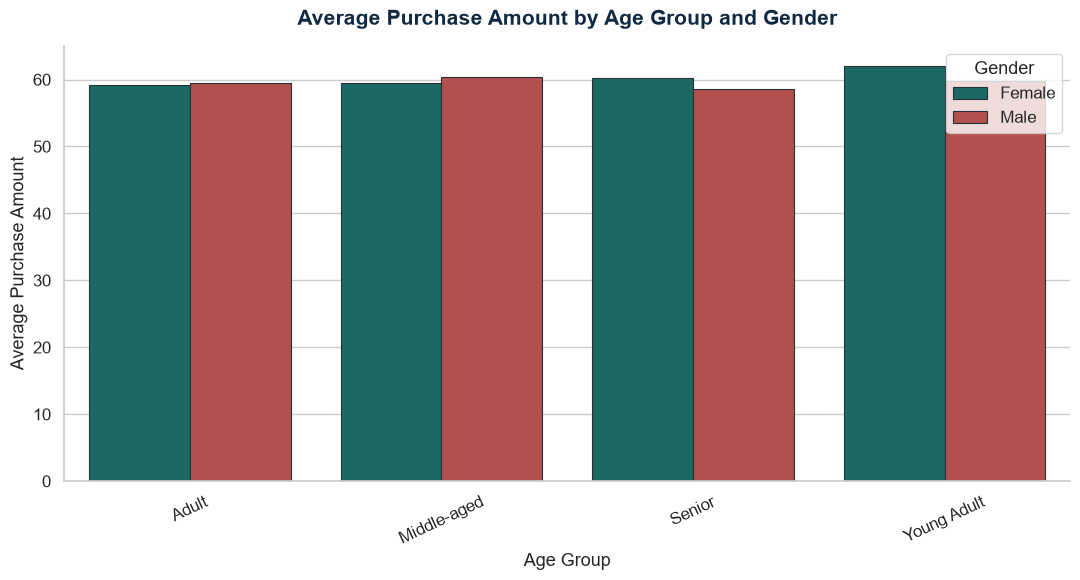

In [121]:
# AVERAGE PURCHASE AMOUNT BY GENDER AND AGE GROUP

spend_by_age_gender = analysis_df.groupby(
    ["age_group", "gender"], observed=False
)["purchase_amount"].mean().reset_index()

# Different dark colors for gender comparison
gender_colors = {
    "Female": "#0F766E",  # Dark teal
    "Male": "#C2413B"     # Dark coral
}

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=spend_by_age_gender,
    x="age_group",
    y="purchase_amount",
    hue="gender",
    hue_order=["Female", "Male"],
    palette=gender_colors,
    edgecolor="#263238",
    linewidth=0.8
)

plt.title(
    "Average Purchase Amount by Age Group and Gender",
    fontsize=15,
    fontweight="bold",
    color="#102A43",
    pad=15
)

plt.xlabel("Age Group")
plt.ylabel("Average Purchase Amount")
plt.xticks(rotation=25)
plt.legend(title="Gender", frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

In [99]:
category_analysis = analysis_df.groupby("category").agg(
    purchase_records=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean"),
    average_rating=("review_rating", "mean")
).reset_index().sort_values("total_revenue", ascending=False)

display(category_analysis.round(2))

,category,purchase_records,total_revenue,average_purchase,average_rating
1,Clothing,1737,104264,60.03,3.72
0,Accessories,1240,74200,59.84,3.77
2,Footwear,599,36093,60.26,3.79
3,Outerwear,324,18524,57.17,3.75


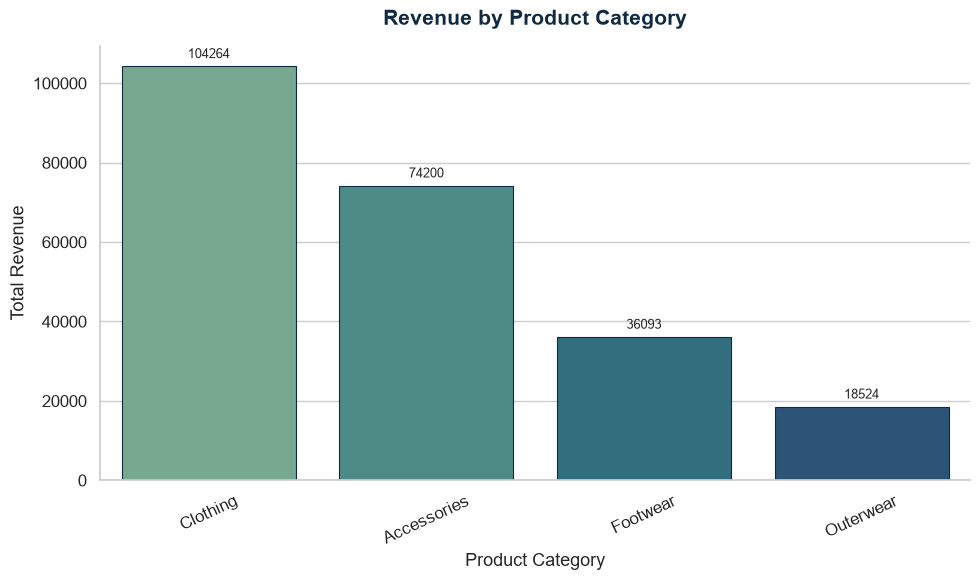

In [122]:
# REVENUE BY PRODUCT CATEGORY

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=category_analysis,
    x="category",
    y="total_revenue",
    hue="category",
    palette="crest",
    edgecolor="#102A43",
    linewidth=0.8,
    legend=False
)

plt.title(
    "Revenue by Product Category",
    fontsize=15,
    fontweight="bold",
    color="#102A43",
    pad=15
)

plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=25)

# Add revenue labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()

In [124]:
product_analysis = analysis_df.groupby("item_purchased").agg(
    purchase_records=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean"),
    average_rating=("review_rating", "mean")
).reset_index()

top_products_revenue = product_analysis.sort_values("total_revenue", ascending=False).head(10)
top_products_volume = product_analysis.sort_values("purchase_records", ascending=False).head(10)

print("Top 10 products by revenue:")
display(top_products_revenue.round(2))

print("Top 10 products by number of records:")
display(top_products_volume.round(2))

Top 10 products by revenue:


,item_purchased,purchase_records,total_revenue,average_purchase,average_rating
2,Blouse,171,10410,60.88,3.68
16,Shirt,169,10332,61.14,3.62
5,Dress,166,10320,62.17,3.75
13,Pants,171,10090,59.01,3.72
12,Jewelry,171,10010,58.54,3.76
22,Sunglasses,161,9649,59.93,3.75
1,Belt,161,9635,59.84,3.76
15,Scarf,157,9561,60.90,3.71
23,Sweater,164,9462,57.70,3.76
18,Shorts,157,9433,60.08,3.71


Top 10 products by number of records:


,item_purchased,purchase_records,total_revenue,average_purchase,average_rating
2,Blouse,171,10410,60.88,3.68
13,Pants,171,10090,59.01,3.72
12,Jewelry,171,10010,58.54,3.76
16,Shirt,169,10332,61.14,3.62
5,Dress,166,10320,62.17,3.75
23,Sweater,164,9462,57.70,3.76
10,Jacket,163,9249,56.74,3.76
1,Belt,161,9635,59.84,3.76
4,Coat,161,9275,57.61,3.73
22,Sunglasses,161,9649,59.93,3.75


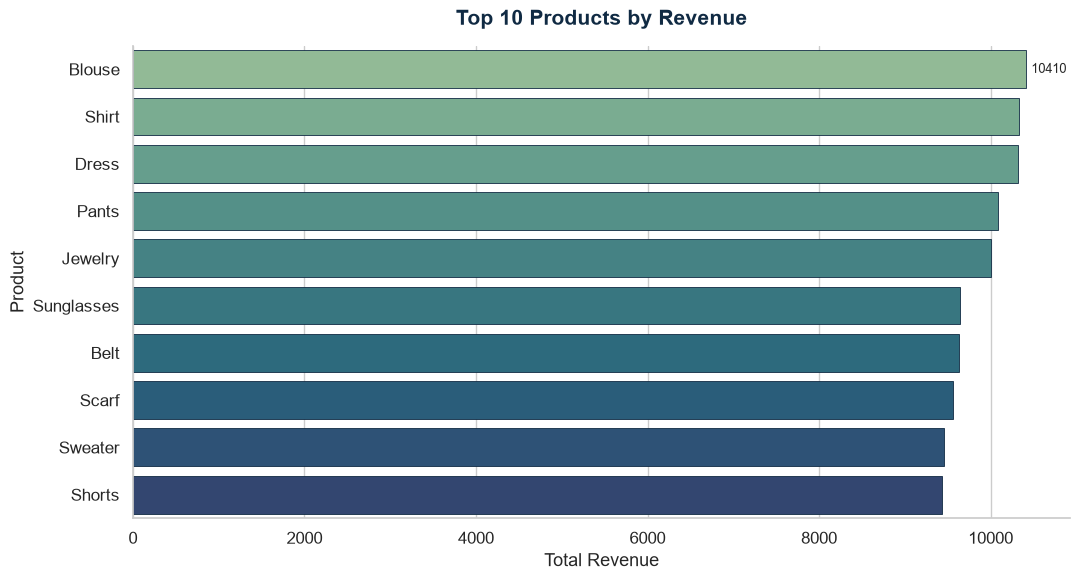

In [125]:
# TOP 10 PRODUCTS BY REVENUE

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_products_revenue,
    x="total_revenue",
    y="item_purchased",
    hue="item_purchased",
    palette="crest",
    edgecolor="#102A43",
    linewidth=0.6,
    legend=False
)

plt.title(
    "Top 10 Products by Revenue",
    fontsize=15,
    fontweight="bold",
    color="#102A43",
    pad=15
)

plt.xlabel("Total Revenue")
plt.ylabel("Product")

# Add revenue values to bars
ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=4,
    fontsize=9
)

sns.despine()
plt.tight_layout()
plt.show()

In [103]:
discount_analysis = analysis_df.groupby("discount_applied").agg(
    purchase_records=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index()

discount_analysis["record_percentage"] = (
    discount_analysis["purchase_records"] / len(analysis_df) * 100
)

display(discount_analysis.round(2))

,discount_applied,purchase_records,total_revenue,average_purchase,record_percentage
0,No,2223,133670,60.13,57.00
1,Yes,1677,99411,59.28,43.00


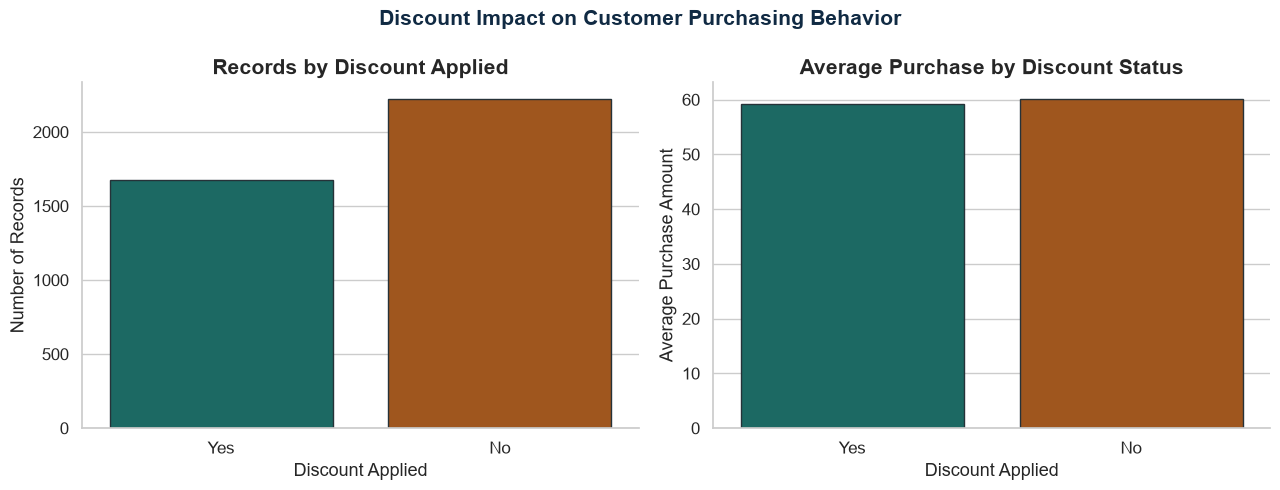

In [126]:
# DISCOUNT ANALYSIS

discount_colors = {
    "Yes": "#0F766E",  # Dark teal
    "No": "#B45309"    # Dark amber
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Customer records by discount status
sns.barplot(
    data=discount_analysis,
    x="discount_applied",
    y="purchase_records",
    hue="discount_applied",
    palette=discount_colors,
    order=["Yes", "No"],
    legend=False,
    edgecolor="#263238",
    ax=axes[0]
)

axes[0].set_title("Records by Discount Applied", fontweight="bold")
axes[0].set_xlabel("Discount Applied")
axes[0].set_ylabel("Number of Records")

# 2. Average purchase by discount status
sns.barplot(
    data=discount_analysis,
    x="discount_applied",
    y="average_purchase",
    hue="discount_applied",
    palette=discount_colors,
    order=["Yes", "No"],
    legend=False,
    edgecolor="#263238",
    ax=axes[1]
)

axes[1].set_title("Average Purchase by Discount Status", fontweight="bold")
axes[1].set_xlabel("Discount Applied")
axes[1].set_ylabel("Average Purchase Amount")

plt.suptitle(
    "Discount Impact on Customer Purchasing Behavior",
    fontsize=15,
    fontweight="bold",
    color="#102A43"
)

sns.despine()
plt.tight_layout()
plt.show()

In [105]:
subscription_analysis = analysis_df.groupby("subscription_status").agg(
    customer_count=("customer_id", "nunique"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index()

subscription_analysis["customer_percentage"] = (
    subscription_analysis["customer_count"] / analysis_df["customer_id"].nunique() * 100
)

display(subscription_analysis.round(2))

,subscription_status,customer_count,total_revenue,average_purchase,customer_percentage
0,No,2847,170436,59.87,73.00
1,Yes,1053,62645,59.49,27.00


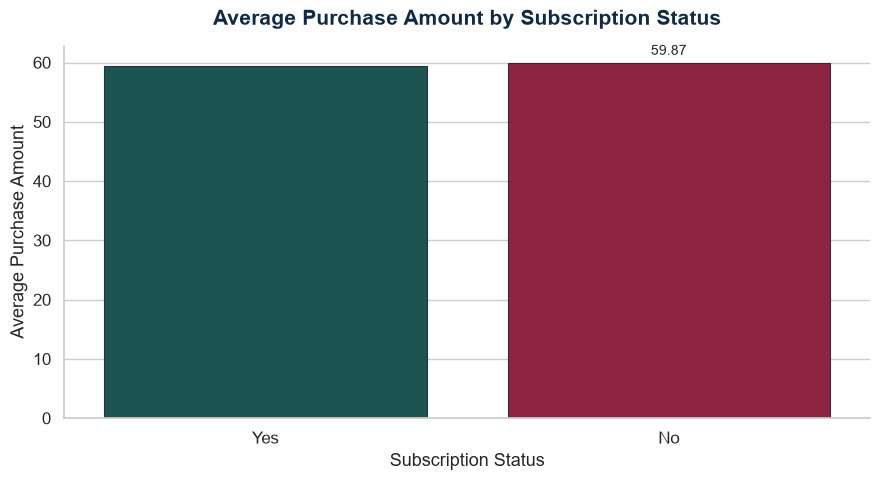

In [127]:
# AVERAGE PURCHASE AMOUNT BY SUBSCRIPTION STATUS

subscription_colors = {
    "Yes": "#115E59",  # Dark teal
    "No": "#9F1239"    # Dark rose
}

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=subscription_analysis,
    x="subscription_status",
    y="average_purchase",
    hue="subscription_status",
    palette=subscription_colors,
    order=["Yes", "No"],
    legend=False,
    edgecolor="#263238",
    linewidth=0.8
)

plt.title(
    "Average Purchase Amount by Subscription Status",
    fontsize=15,
    fontweight="bold",
    color="#102A43",
    pad=15
)

plt.xlabel("Subscription Status")
plt.ylabel("Average Purchase Amount")

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=4,
    fontsize=10
)

sns.despine()
plt.tight_layout()
plt.show()

In [107]:
frequency_analysis = analysis_df.groupby("frequency_of_purchases").agg(
    customer_count=("customer_id", "nunique"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index().sort_values("customer_count", ascending=False)

display(frequency_analysis.round(2))

,frequency_of_purchases,customer_count,total_revenue,average_purchase
2,Every 3 Months,584,35088,60.08
0,Annually,572,34419,60.17
5,Quarterly,563,33771,59.98
4,Monthly,553,32810,59.33
1,Bi-Weekly,547,33200,60.69
3,Fortnightly,542,32007,59.05
6,Weekly,539,31786,58.97


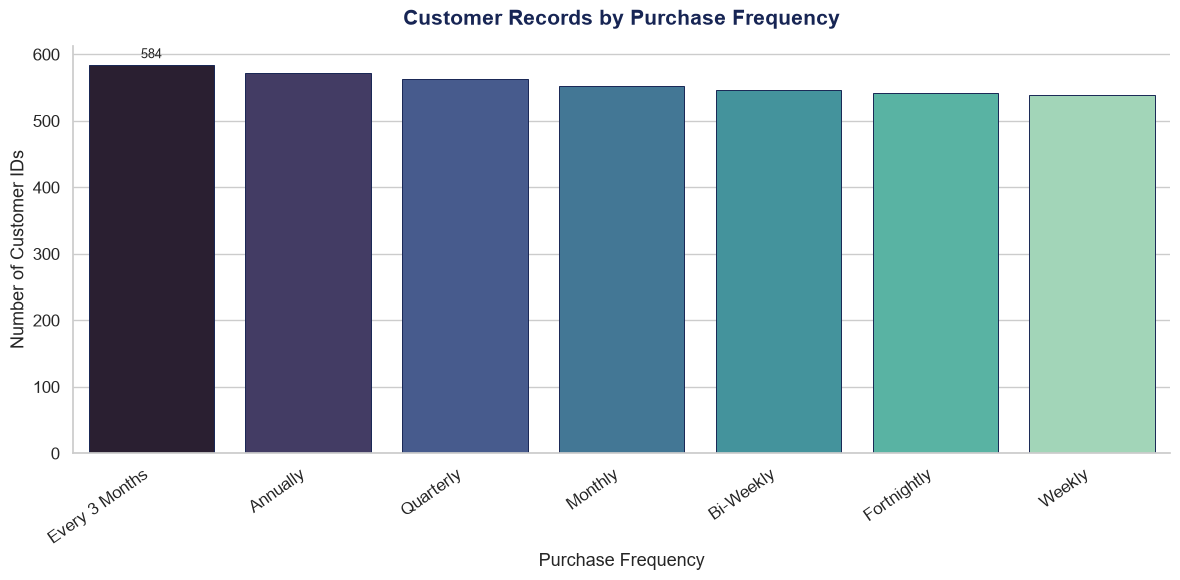

In [128]:
# CUSTOMER RECORDS BY PURCHASE FREQUENCY

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=frequency_analysis,
    x="frequency_of_purchases",
    y="customer_count",
    hue="frequency_of_purchases",
    palette="mako",
    edgecolor="#172554",
    linewidth=0.7,
    legend=False
)

plt.title(
    "Customer Records by Purchase Frequency",
    fontsize=15,
    fontweight="bold",
    color="#172554",
    pad=15
)

plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customer IDs")
plt.xticks(rotation=35, ha="right")

# Display values above bars
ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3,
    fontsize=9
)

sns.despine()
plt.tight_layout()
plt.show()

In [109]:
# Segment customers using previous_purchases as in the SQL analysis
analysis_df["customer_segment"] = np.select(
    [
        analysis_df["previous_purchases"] == 1,
        analysis_df["previous_purchases"].between(2, 10)
    ],
    ["New", "Returning"],
    default="Loyal"
)

loyalty_analysis = analysis_df.groupby("customer_segment").agg(
    customer_count=("customer_id", "nunique"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean"),
    average_previous_purchases=("previous_purchases", "mean")
).reset_index()

display(loyalty_analysis.round(2))

,customer_segment,customer_count,total_revenue,average_purchase,average_previous_purchases
0,Loyal,3116,185517,59.54,30.40
1,New,83,4853,58.47,1.00
2,Returning,701,42711,60.93,5.81


In [110]:
payment_analysis = analysis_df.groupby("payment_method").agg(
    transaction_count=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index().sort_values("total_revenue", ascending=False)

shipping_analysis = analysis_df.groupby("shipping_type").agg(
    transaction_count=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index().sort_values("total_revenue", ascending=False)

print("Payment method analysis:")
display(payment_analysis.round(2))

print("Shipping type analysis:")
display(shipping_analysis.round(2))

Payment method analysis:


,payment_method,transaction_count,total_revenue,average_purchase
2,Credit Card,671,40310,60.07
4,PayPal,677,40109,59.25
1,Cash,670,40002,59.70
3,Debit Card,636,38742,60.92
5,Venmo,634,37374,58.95
0,Bank Transfer,612,36544,59.71


Shipping type analysis:


,shipping_type,transaction_count,total_revenue,average_purchase
2,Free Shipping,675,40777,60.41
1,Express,646,39067,60.48
5,Store Pickup,650,38931,59.89
4,Standard,654,38233,58.46
0,2-Day Shipping,627,38080,60.73
3,Next Day Air,648,37993,58.63


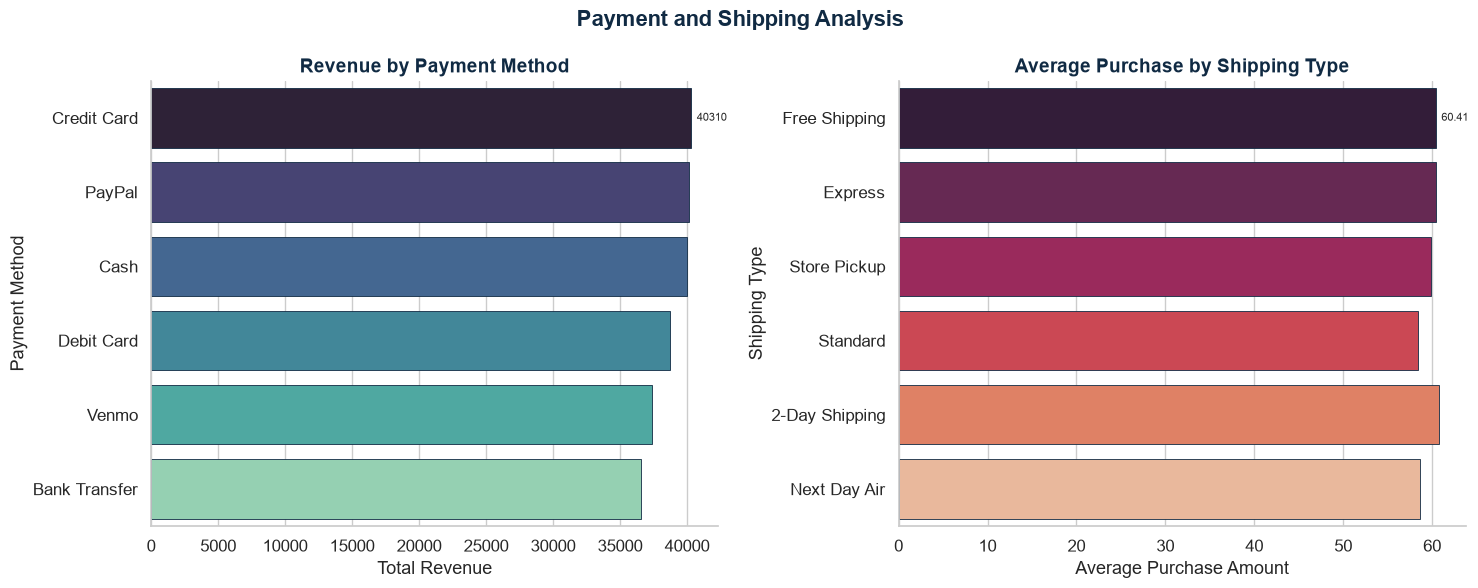

In [129]:
# PAYMENT METHOD AND SHIPPING TYPE ANALYSIS

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Revenue by Payment Method
sns.barplot(
    data=payment_analysis,
    x="total_revenue",
    y="payment_method",
    hue="payment_method",
    palette="mako",
    edgecolor="#102A43",
    linewidth=0.6,
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Revenue by Payment Method",
    fontsize=14,
    fontweight="bold",
    color="#102A43"
)
axes[0].set_xlabel("Total Revenue")
axes[0].set_ylabel("Payment Method")

# Add revenue labels
axes[0].bar_label(
    axes[0].containers[0],
    fmt="%.0f",
    padding=4,
    fontsize=8
)

# 2. Average Purchase by Shipping Type
sns.barplot(
    data=shipping_analysis,
    x="average_purchase",
    y="shipping_type",
    hue="shipping_type",
    palette="rocket",
    edgecolor="#102A43",
    linewidth=0.6,
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Average Purchase by Shipping Type",
    fontsize=14,
    fontweight="bold",
    color="#102A43"
)
axes[1].set_xlabel("Average Purchase Amount")
axes[1].set_ylabel("Shipping Type")

# Add average purchase labels
axes[1].bar_label(
    axes[1].containers[0],
    fmt="%.2f",
    padding=4,
    fontsize=8
)

plt.suptitle(
    "Payment and Shipping Analysis",
    fontsize=16,
    fontweight="bold",
    color="#102A43"
)

sns.despine()
plt.tight_layout()
plt.show()

In [112]:
season_analysis = analysis_df.groupby("season").agg(
    purchase_records=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index().sort_values("total_revenue", ascending=False)

location_analysis = analysis_df.groupby("location").agg(
    purchase_records=("customer_id", "count"),
    total_revenue=("purchase_amount", "sum"),
    average_purchase=("purchase_amount", "mean")
).reset_index().sort_values("total_revenue", ascending=False)

print("Seasonal analysis:")
display(season_analysis.round(2))

print("Top 10 locations by revenue:")
display(location_analysis.head(10).round(2))

Seasonal analysis:


,season,purchase_records,total_revenue,average_purchase
0,Fall,975,60018,61.56
1,Spring,999,58679,58.74
3,Winter,971,58607,60.36
2,Summer,955,55777,58.41


Top 10 locations by revenue:


,location,purchase_records,total_revenue,average_purchase
25,Montana,96,5784,60.25
12,Illinois,92,5617,61.05
4,California,95,5605,59.00
11,Idaho,93,5587,60.08
27,Nevada,87,5514,63.38
0,Alabama,89,5261,59.11
31,New York,87,5257,60.43
33,North Dakota,83,5220,62.89
47,West Virginia,81,5174,63.88
26,Nebraska,87,5172,59.45


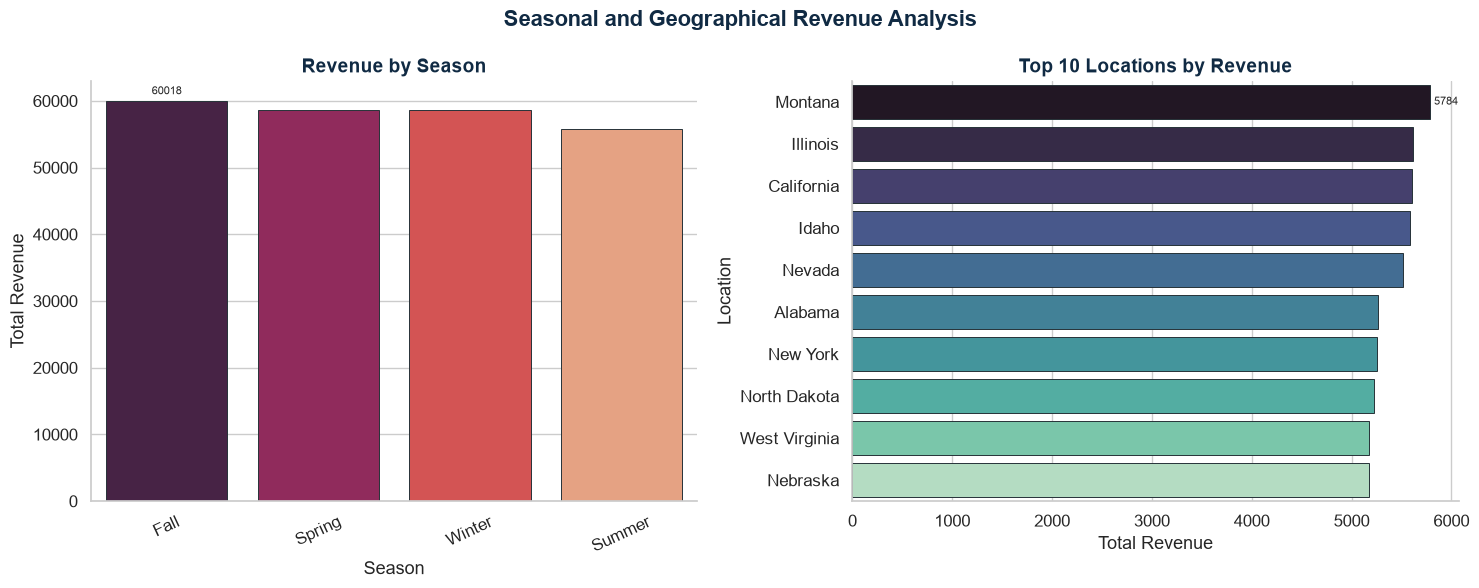

In [130]:
# SEASONAL AND LOCATION-WISE REVENUE ANALYSIS

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Revenue by Season
sns.barplot(
    data=season_analysis,
    x="season",
    y="total_revenue",
    hue="season",
    palette="rocket",
    edgecolor="#263238",
    linewidth=0.7,
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    "Revenue by Season",
    fontsize=14,
    fontweight="bold",
    color="#102A43"
)
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Total Revenue")
axes[0].tick_params(axis="x", rotation=25)

axes[0].bar_label(
    axes[0].containers[0],
    fmt="%.0f",
    padding=3,
    fontsize=8
)

# 2. Top 10 Locations by Revenue
top_locations = location_analysis.head(10)

sns.barplot(
    data=top_locations,
    x="total_revenue",
    y="location",
    hue="location",
    palette="mako",
    edgecolor="#263238",
    linewidth=0.7,
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Top 10 Locations by Revenue",
    fontsize=14,
    fontweight="bold",
    color="#102A43"
)
axes[1].set_xlabel("Total Revenue")
axes[1].set_ylabel("Location")

axes[1].bar_label(
    axes[1].containers[0],
    fmt="%.0f",
    padding=3,
    fontsize=8
)

plt.suptitle(
    "Seasonal and Geographical Revenue Analysis",
    fontsize=16,
    fontweight="bold",
    color="#102A43"
)

sns.despine()
plt.tight_layout()
plt.show()

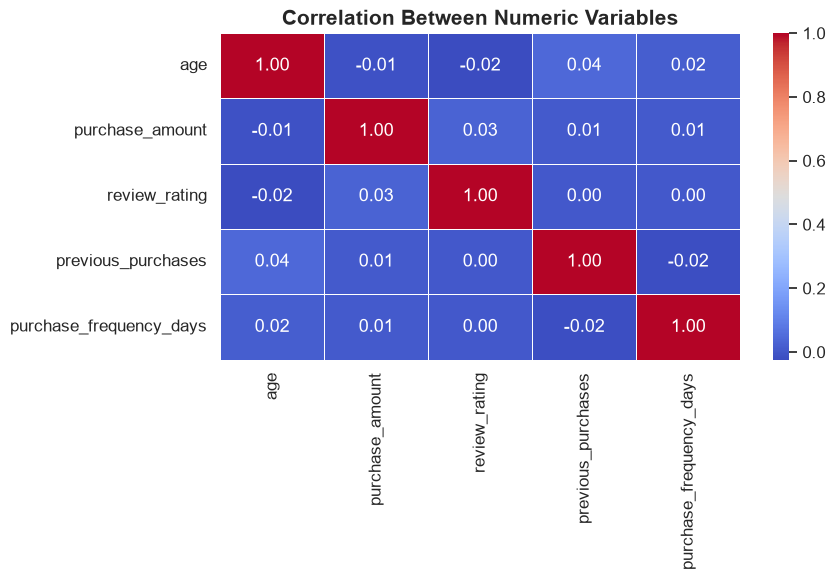

In [114]:
correlation_columns = [
    "age", "purchase_amount", "review_rating",
    "previous_purchases", "purchase_frequency_days"
]

correlation_matrix = analysis_df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()

In [115]:
kpi_summary.to_csv("customer_kpi_summary.csv", index=False)
gender_analysis.to_csv("gender_analysis.csv", index=False)
age_group_analysis.to_csv("age_group_analysis.csv", index=False)
category_analysis.to_csv("category_analysis.csv", index=False)
product_analysis.to_csv("product_analysis.csv", index=False)
discount_analysis.to_csv("discount_analysis.csv", index=False)
subscription_analysis.to_csv("subscription_analysis.csv", index=False)
payment_analysis.to_csv("payment_analysis.csv", index=False)
shipping_analysis.to_csv("shipping_analysis.csv", index=False)
season_analysis.to_csv("season_analysis.csv", index=False)
location_analysis.to_csv("location_analysis.csv", index=False)

print("Analysis summary files exported successfully!")

Analysis summary files exported successfully!
